# Footprint and light-curve animation for a single transient

## Overview

For **one simulated transient**, this notebook shows what UVEX actually did at the event's site:

- a **sky panel** with the UVEX fields observed around the event during a time window, shaded by the
  total exposure time each patch of sky has accumulated, and
- a **light-curve panel** with the event's noiseless theory curve, its simulated detections, and the
  upper limits from the observations that did not detect it, in every band.

It produces two figures:

1. A **static figure**: the *total* exposure-time map over the whole window next to the *complete* light curve.
2. An **animation**: the same two panels as a time-lapse. The exposure map builds up observation by observation (the
   latest footprints are outlined) while a vertical line sweeps across the light curve. The light curve starts as the
   bare theory curve, and each simulated measurement is placed onto it at the moment its observation happens. The
   marker at the event's position grows and shrinks with the event's brightness in one band.

The sky panel is drawn on a real WCS (a gnomonic projection centred on the event, north up and east to the left), so
its axes are right ascension and declination, and the exposure map and the footprint outlines share one projection.

### Required data

| Item | Where it comes from | Default |
| --- | --- | --- |
| An `EventCatalog` | the `final_catalog.ecsv` of a pipeline run (`uvex-transients run ...`), or a release download | the catalog of release `v0.6.5alpha`: only events that survived the magnitude and SNR cuts |
| The `SurveySchedule` the catalog was generated against | `uvex_transients.surveys.get_schedule` | the package's default schedule |
| The mission (bandpasses and detector) | `uvex_transients.missions.get_mission` | `"uvex_fast"` |

By default the notebook downloads the `final_catalog.ecsv` of release `v0.6.5alpha` (2.4 MB) with
`uvex_transients.utils.get_results`. That catalog holds only the events that survived the pipeline's cuts, so every
event in it was detected. Set `RELEASE_TAG` to use another release (not every release carries the primary run's
catalog, and the newest, `RELEASE_TAG = None`, may not), or `EVENTS_PATH` to a file path to use your own catalog.
`EVENTS_PATH = None` uses the small packaged example catalog instead. That one is *pre-cut*: a raw Monte Carlo draw
from the event rates, so many of its events were never detectable, but it works offline.

The catalog stores only a transient *type name* per event, so `TRANSIENT_CLASSES` maps those names to classes. If your
run used custom transient settings, build the matching transient instance yourself so the light curve agrees with the
run that produced the catalog.

### Caveats

- The schedule must be the one the catalog was generated against, otherwise the events fall in the wrong fields.
- The event's photometry is regenerated from its stored seed with the **installed** code, so the points are the
  pipeline's own only if the installed version matches the one that made the catalog. If you change an SED model
  or its priors after the release was made, events of that type will differ from the catalog.
- Writing an `mp4` needs `ffmpeg` on your path. If it is missing the notebook falls back to a `gif`, which is
  slower to write and larger.
- The style cell uses LaTeX for text when a TeX installation is found, and matplotlib's own Computer Modern otherwise.
- The sky panel is a flat gnomonic cutout, so keep `CUTOUT_HALF_WIDTH` to a few degrees.

## Setup and Configuration

In [1]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord, SkyOffsetFrame
from astropy.wcs import WCS
from IPython import display as ipython_display
from IPython.display import Image, Video
from m4opt.fov import contains, footprint
from matplotlib import animation
from matplotlib.collections import PolyCollection
from matplotlib.lines import Line2D
from regions import Regions

from uvex_transients.missions import get_mission
from uvex_transients.simulation import EventCatalog, get_example_event_catalog
from uvex_transients.surveys import get_schedule
from uvex_transients.transients import (
    Kilonova,
    LowLuminosityGRB,
    LuminousFastBlueOpticalTransient,
    MagnetarSLSNe,
    TidalDisruptionEvent,
    TypeIaSNe,
    TypeIbSNe,
    TypeIcBLSNe,
    TypeIcSNe,
    TypeIIbSNe,
    TypeIIPSNe,
)
from uvex_transients.utils import get_results
from uvex_transients.utils.plotting import get_band_color, plot_band_light_curve

[uvex_transients]-INFO: Downsampled a bandpass table from 11000 to 353 points (worst-case 0.00089 mag over 1500-50000 K, mass rescale 0.999041).


[uvex_transients]-INFO: Downsampled a bandpass table from 11000 to 366 points (worst-case 0.00023 mag over 1500-50000 K, mass rescale 0.999667).


In [2]:
# ---------------------------------------------------------------------------------------------- #
# UVEX Transients notebook style. Copy this cell unchanged into every notebook (see the readme), #
# so that all of them look the same.                                                             #
# ---------------------------------------------------------------------------------------------- #
import shutil

import matplotlib as mpl
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap

# The UVEX logo gradient runs from blue (top) to violet (bottom). These are its colors, sampled from the logo files.
UVEX_BLUE = "#72AEFF"
UVEX_VIOLET = "#AF6EFF"
# The same hues, deepened so that thin lines and small markers stay legible on a white background.
UVEX_BLUE_DEEP = "#3B87EB"
UVEX_VIOLET_DEEP = "#9742ED"
UVEX_NAVY = "#0A0B1E"  # A dark background for images and maps.

# Default color cycle: the two logo hues first, then accents that stay apart from them and from each other.
UVEX_CYCLE = [UVEX_BLUE_DEEP, UVEX_VIOLET_DEEP, "#13A89E", "#F2A93B", "#E5509A", "#475569"]

# Sequential colormap for images and maps, "uvex": indigo (low) through violet and blue to pale (high). Its lightness
# rises steadily, so it also reads in grayscale. The low end is lighter than UVEX_NAVY, so faint pixels stay visible.
UVEX_CMAP = LinearSegmentedColormap.from_list("uvex", ["#2A2078", "#4B2BA8", UVEX_VIOLET, UVEX_BLUE, "#EAF4FF"])
mpl.colormaps.register(UVEX_CMAP, name="uvex", force=True)

# Text is set with LaTeX when a TeX installation is found, and with matplotlib's own Computer Modern look-alike if not.
USE_LATEX = shutil.which("latex") is not None and shutil.which("dvipng") is not None

mpl.rcParams.update(
    {
        # --- Publication style (AAS two-column-ish, LaTeX/Computer Modern) ---
        "text.usetex": USE_LATEX,
        "text.latex.preamble": r"\usepackage{amsmath,amssymb}",
        "font.family": "serif",
        "font.serif": ["Computer Modern Roman", "cmr10", "DejaVu Serif"],
        "mathtext.fontset": "cm",
        "axes.formatter.use_mathtext": True,
        "axes.unicode_minus": False,
        "font.size": 10,
        "axes.labelsize": 10,
        "axes.titlesize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 8,
        "axes.linewidth": 0.6,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.top": True,
        "ytick.right": True,
        "xtick.major.size": 3,
        "xtick.minor.size": 1.5,
        "ytick.major.size": 3,
        "ytick.minor.size": 1.5,
        "lines.linewidth": 1.0,
        "figure.dpi": 150,
        "savefig.dpi": 300,
        # --- UVEX colors ---
        "axes.prop_cycle": cycler(color=UVEX_CYCLE),
        "image.cmap": "uvex",
        "legend.frameon": False,
    }
)


def tex(text):
    """Escape the characters LaTeX treats specially (_ % & #), so plain text can go into labels when LaTeX is on."""
    if mpl.rcParams["text.usetex"]:
        for char in "_%&#":
            text = text.replace(char, "\\" + char)
    return text

In [3]:
# ------------------------------------------------------------------ #
# User settings. Everything you are likely to want to change is here. #
# ------------------------------------------------------------------ #

# --- Data ---
# EVENTS_PATH: "release" downloads a GitHub release's final catalog, whose events all survived the cuts.
#              None uses the small packaged example catalog, which is pre-cut (many events were never detectable).
#              A file path loads your own EventCatalog.
EVENTS_PATH = "release"
RELEASE_TAG = "v0.6.5alpha"  # The release to download. None: the newest, which may not carry the catalog.
EVENT_ID = 344093  # `event_id` to show. In v0.6.5alpha, 344093 is an SLSN at z~0.66 with many detections in both bands.
SCHEDULE_NAME = None  # Name of the schedule the catalog was made with. None: the package default.
MISSION_NAME = "uvex_fast"  # The mission whose bandpasses and detector the photometry is simulated with.

# Maps the `transient_type` names stored in a catalog to the classes that realise them. The example catalog
# uses "slsn", the full-run config uses "slsne"; both are listed.
TRANSIENT_CLASSES = {
    "kilonova": Kilonova,
    "tde": TidalDisruptionEvent,
    "lfbot": LuminousFastBlueOpticalTransient,
    "llgrb": LowLuminosityGRB,
    "iip_sne": TypeIIPSNe,
    "iib_sne": TypeIIbSNe,
    "ib_sne": TypeIbSNe,
    "ic_sne": TypeIcSNe,
    "icbl_sne": TypeIcBLSNe,
    "slsn": MagnetarSLSNe,
    "slsne": MagnetarSLSNe,
    "ia_sne": TypeIaSNe,
}

# --- Time window ---
WINDOW = (-10, 150)  # (start, stop) in days since explosion. None: the transient's own photometry window.

# --- Sky panel ---
CUTOUT_HALF_WIDTH = 4.0 * u.deg  # Half-width of the square sky cutout centred on the event.
GRID_SIZE = 256  # Pixels per side of the exposure-time map. Raise for sharper chip gaps, lower for speed.
EXPOSURE_CMAP = "uvex"  # A matplotlib colormap name. "uvex" is the standard sequential map from the style cell.
SHOW_EVENT_FOOTPRINTS = False  # Outline every footprint that covered the event. Busy for well-observed events.
STAR_BAND = (
    "NUV"  # Band whose theory brightness sets the size of the event marker in the animation. None: the first band.
)
STAR_SIZE = (4, 24)  # Marker size in points when the event is invisible and when it is at its brightest in STAR_BAND.

# --- Light-curve panel ---
BANDS = None  # List of band names to show, e.g. ["NUV"]. None: every band of the mission.
BAND_COLORS = {
    "NUV": UVEX_BLUE_DEEP,
    "FUV": UVEX_VIOLET_DEEP,
}  # Shorter wavelength, more violet. Others: package colors.
SNR_THRESHOLD = 5.0  # SNR above which a point is drawn as a detection rather than an upper limit.
N_THEORY = 600  # Number of time samples of the noiseless theory curve.

# --- Output ---
OUTPUT_DIR = Path("../../results")  # Repo-level results/ (gitignored). Where figures and the animation are written.
SAVE_STATIC = True  # Write the static figure to disk.
MAKE_ANIMATION = True  # Set False to skip the (slower) animation.
ANIMATION_FORMAT = "mp4"  # "mp4" (needs ffmpeg) or "gif".
ANIMATION_DPI = 200  # Resolution of the animation frames.
N_FRAMES = 240  # Frames spaced evenly in time. Every observation also gets a frame of its own, so none arrive together.
FPS = 20  # Frames per second of the animation.
FIG_SIZE = (8, 3.6)  # Figure size in inches. The style cell is tuned for figures of about this width.

In [4]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def band_color(band):
    """Return the color of a band: BAND_COLORS first, then the package's shared band colors."""
    return BAND_COLORS.get(band, get_band_color(band))

## Data Loading

The schedule, mission and event catalog are loaded here, and the chosen event is rebuilt from its catalog row.
Building an `Event` is cheap: it stores only the event's position, redshift, explosion time and parameter seed.

In [5]:
schedule = get_schedule(SCHEDULE_NAME)
mission = get_mission(MISSION_NAME)

if EVENTS_PATH is None:
    catalog = get_example_event_catalog()
elif EVENTS_PATH == "release":
    catalog = EventCatalog.from_disk(get_results(["events"], tag=RELEASE_TAG)["events"])
else:
    catalog = EventCatalog.from_disk(EVENTS_PATH)

print(f"Catalog: {len(catalog)} events. Schedule: {schedule}")

[uvex_transients]-INFO: Fetching schedule '<url>' from https://raw.githubusercontent.com/m4opt/uvex-scheduler/refs/tags/v0.6.0/tables/plan.ecsv (cache=True).


[uvex_transients]-INFO: Schedule fetch complete: 112803 rows.


[uvex_transients]-INFO: Querying https://api.github.com/repos/TransientsExtragalactic/uvex-transients/releases for the release list.


[uvex_transients]-INFO: Results asset final_catalog.ecsv already present at /Users/ediggins/Library/Caches/uvex_transients/results/v0.6.5alpha/final_catalog.ecsv.


[uvex_transients]-INFO: Reading event catalog from /Users/ediggins/Library/Caches/uvex_transients/results/v0.6.5alpha/final_catalog.ecsv.


[uvex_transients]-INFO: Read event catalog (12291 events) from /Users/ediggins/Library/Caches/uvex_transients/results/v0.6.5alpha/final_catalog.ecsv.


Catalog: 12291 events. Schedule: <SurveySchedule n_actions=112803 start_time='2030-01-01 00:00:00.000' end_time='2032-01-01 06:09:05.716'>


In [6]:
row = np.flatnonzero(catalog.event_id == EVENT_ID)
if row.size == 0:
    id_range = f"{catalog.event_id.min()} to {catalog.event_id.max()}"
    raise KeyError(f"No event with id {EVENT_ID} in the catalog (ids run from {id_range}).")

type_name = str(catalog.transient_type[row[0]])
if type_name not in TRANSIENT_CLASSES:
    raise KeyError(f"No class registered for transient type {type_name!r}; add it to TRANSIENT_CLASSES.")

event = catalog.get_events(EVENT_ID, {type_name: TRANSIENT_CLASSES[type_name]()}, schedule)
print(event)
print(f"RA, Dec = {event.coord.ra.deg:.4f}, {event.coord.dec.deg:.4f} deg;  explosion at {event.t_explosion.iso}")

<Event id=344093 type='slsne' z=0.6606 n_observations=50>
RA, Dec = 2.6284, -33.3891 deg;  explosion at 2031-04-07 12:26:32.188


## Data Processing

Four things are prepared:

1. **The window and the fields.** Every observation the schedule made within the window and near the event, not just the
   ones that covered it, so the sky panel shows the neighbouring fields too.
2. **The WCS and the exposure-time maps.** A gnomonic WCS centred on the event defines the pixel grid. Each observation's
   footprint is tested against the sky position of every pixel, and the cumulative exposure time is stored after every
   observation.
3. **The footprint outlines**, projected through the same WCS.
4. **The photometry.** The event's simulated light curve and its noiseless theory curve, per band.

In [7]:
# --- The time window, in days since explosion ---
pre = event.transient.photometry_pre_window
post = event.transient.photometry_post_window
t_start_d, t_stop_d = (-pre.to_value(u.day), post.to_value(u.day)) if WINDOW is None else map(float, WINDOW)
t_start = event.t_explosion + t_start_d * u.day
t_stop = event.t_explosion + t_stop_d * u.day

# --- Observations near the event in that window ---
rows = schedule.get_rows_between_times(t_start, t_stop)
rows = rows[np.asarray(rows["action"]).astype(str) == "observe"]
reach = np.sqrt(2) * CUTOUT_HALF_WIDTH + schedule.bounding_radius
rows = rows[event.coord.separation(rows["target_coord"]) < reach]
rel_start = (rows["start_time"] - event.t_explosion).to_value(u.day)
duration_h = rows["duration"].to_value(u.hour)
print(f"{len(rows)} observations within {reach:.1f} of the event between {t_start_d:.1f} and {t_stop_d:.1f} days.")

173 observations within 8.3 deg of the event between -10.0 and 150.0 days.


In [8]:
# --- A WCS for the cutout: gnomonic (TAN) projection centred on the event, north up and east to the left ---
n_pix = GRID_SIZE
pixel_scale = (2 * CUTOUT_HALF_WIDTH / n_pix).to_value(u.deg)
cutout_wcs = WCS(naxis=2)
cutout_wcs.wcs.ctype = ["RA---TAN", "DEC--TAN"]
cutout_wcs.wcs.crval = [event.coord.ra.deg, event.coord.dec.deg]
cutout_wcs.wcs.crpix = [(n_pix + 1) / 2, (n_pix + 1) / 2]  # FITS pixels count from 1: the event is at the image centre.
cutout_wcs.wcs.cdelt = [-pixel_scale, pixel_scale]
cutout_wcs.wcs.cunit = ["deg", "deg"]
cutout_wcs.array_shape = (n_pix, n_pix)
event_xy = cutout_wcs.world_to_pixel(event.coord)  # Pixel coordinates (0-based) of the event.

# The sky position of every pixel centre.
pixel_x, pixel_y = np.meshgrid(np.arange(n_pix), np.arange(n_pix))
pixel_sky = cutout_wcs.pixel_to_world(pixel_x.ravel(), pixel_y.ravel())

# The first test point is the event itself, so one pass also tells us which observations covered it.
test_points = SkyCoord(
    np.concatenate([[event.coord.ra.deg], pixel_sky.ra.deg]) * u.deg,
    np.concatenate([[event.coord.dec.deg], pixel_sky.dec.deg]) * u.deg,
)

covered = np.zeros((len(rows), test_points.size), dtype=bool)
for i, (target, roll) in enumerate(zip(rows["target_coord"], rows["roll"])):
    # Express the test points in this pointing's own frame, then ask whether the unrotated field of view contains them.
    local = test_points.transform_to(SkyOffsetFrame(origin=target, rotation=roll))
    covered[i] = contains(schedule.fov, SkyCoord(local.lon, local.lat, frame="icrs"))

covers_event = covered[:, 0]
exposure_by_obs = covered[:, 1:].reshape(len(rows), n_pix, n_pix) * duration_h[:, None, None].astype(np.float32)
cumulative_exposure = np.cumsum(exposure_by_obs, axis=0)  # Hours of exposure per pixel after each observation.
total_exposure = cumulative_exposure[-1] if len(rows) else np.zeros((n_pix, n_pix))
print(f"{covers_event.sum()} of those observations covered the event.")
print(f"Peak exposure in the cutout: {total_exposure.max():.2f} h.")

46 of those observations covered the event.
Peak exposure in the cutout: 12.50 h.


In [9]:
# --- Outlines of every observed footprint, projected through the cutout WCS (pixel coordinates) ---
def outlines(regions_per_obs):
    """Return the polygon vertices, in cutout pixel coordinates, of each region of each observation."""
    polygons = []
    for regions in regions_per_obs:
        for region in regions if isinstance(regions, Regions) else [regions]:
            # `footprint` attaches a dimensionless distance to its vertices. Left on, it breaks the change of frame
            # (the outlines land in the wrong place), so keep only the direction.
            vertices = SkyCoord(region.vertices.ra, region.vertices.dec)
            polygons.append(np.column_stack(cutout_wcs.world_to_pixel(vertices)))
    return polygons


outline_by_obs = [outlines([regions]) for regions in footprint(schedule.fov, rows["target_coord"], rows["roll"])]

In [10]:
# --- Simulated photometry and the noiseless theory curve ---
phot = event.simulate_photometry(mission, bands=BANDS)
bands = list(mission.detector.bandpasses) if BANDS is None else list(BANDS)

t_theory = np.linspace(max(t_start_d, 0.0) + 0.05, t_stop_d, N_THEORY) * u.day
theory = {band: event.mag(t_theory, mission, band).value for band in bands}

n_det = int(np.sum((phot["snr"] > SNR_THRESHOLD) & phot["in_model"]))
print(f"{len(phot)} simulated measurements ({n_det} above SNR {SNR_THRESHOLD:g}) in bands {bands}.")
if n_det == 0:
    print("No measurement reaches SNR_THRESHOLD. In a pre-cut catalog this event may never have been detectable;")
    print("in a final catalog, the installed code may differ from the version that made it.")

100 simulated measurements (67 above SNR 5) in bands ['FUV', 'NUV'].


## Visualization

### Static figure

The left panel is the total exposure time each patch of sky received over the window, on the cutout's WCS. The gaps
between the detector chips show up as darker strips, and where neighbouring fields overlap the exposure adds up. The
right panel is the event's complete light curve: the faint line is the noiseless theory curve, filled points are
detections, and open triangles are upper limits.

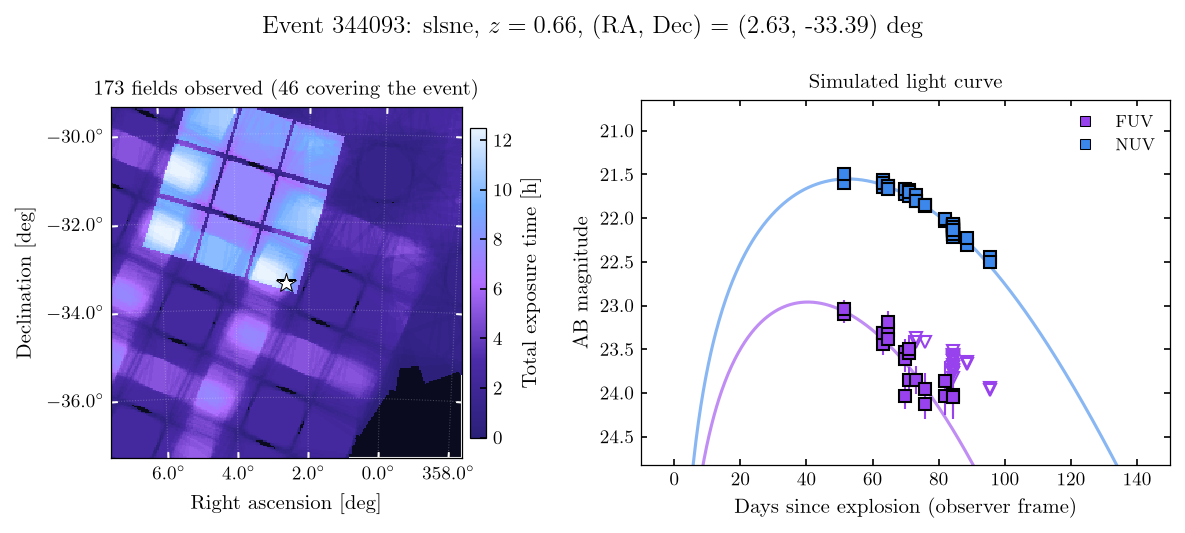

In [11]:
cmap = mpl.colormaps[EXPOSURE_CMAP] if isinstance(EXPOSURE_CMAP, str) else EXPOSURE_CMAP
vmax = max(float(total_exposure.max()), 1e-3)


def make_figure():
    """Create the figure: the sky panel on the cutout WCS, and the light-curve panel."""
    fig = plt.figure(figsize=FIG_SIZE)
    grid_spec = fig.add_gridspec(1, 2, width_ratios=[1, 1.25])
    return fig, fig.add_subplot(grid_spec[0], projection=cutout_wcs), fig.add_subplot(grid_spec[1])


def draw_sky(ax, exposure):
    """Draw the exposure-time map (hours per pixel) with the event marked, and return the image and the star."""
    ax.set_facecolor(UVEX_NAVY)  # Unexposed pixels are masked, so they show this background.
    image = ax.imshow(
        np.ma.masked_less_equal(exposure, 0),
        origin="lower",
        cmap=cmap,
        vmin=0,
        vmax=vmax,
        interpolation="nearest",
        rasterized=True,
    )
    if SHOW_EVENT_FOOTPRINTS:
        edge_polygons = [poly for idx in np.flatnonzero(covers_event) for poly in outline_by_obs[idx]]
        ax.add_collection(
            PolyCollection(edge_polygons, facecolors="none", edgecolors=UVEX_VIOLET, linewidths=0.3, alpha=0.6)
        )
    (star,) = ax.plot(*event_xy, marker="*", ms=10, mfc="w", mec="k", mew=0.5, linestyle="none", zorder=5)
    ax.coords.grid(color="w", alpha=0.25, linestyle=":", linewidth=0.5)
    ax.coords[0].set_axislabel("Right ascension [deg]")
    ax.coords[1].set_axislabel("Declination [deg]")
    for axis in ax.coords:
        axis.set_major_formatter("d.d")
        axis.set_ticks(color="w", direction="in")
    return image, star


def draw_light_curve(ax, show_data=True):
    """Draw the theory curve of every band onto `ax`, and, if `show_data`, the detections and upper limits too."""
    shown = phot if show_data else phot[:0]
    for band in bands:
        plot_band_light_curve(
            ax,
            band,
            shown["rel_time"],
            shown,
            t_theory=t_theory,
            theory_mag=theory[band],
            snr_threshold=SNR_THRESHOLD,
            color=band_color(band),
        )

    # The magnitude range covers the limits and detections inside the window and every band's theory peak, so a source
    # fainter than the survey depth still shows its (undetected) peak, below the limits.
    t_meas = phot["rel_time"].to_value(u.day)
    in_view = (t_meas >= t_start_d) & (t_meas <= t_stop_d)
    detected = (phot["snr"] > SNR_THRESHOLD) & phot["in_model"]
    measured = np.concatenate([np.asarray(phot["mag_lower"])[in_view], np.asarray(phot["ab_mag"])[in_view & detected]])
    theory_peaks = [theory[b][np.isfinite(theory[b])].min() for b in bands if np.isfinite(theory[b]).any()]
    extremes = np.concatenate([measured[np.isfinite(measured)], theory_peaks])
    if extremes.size:
        ax.set_ylim(extremes.max() + 0.7, extremes.min() - 0.7)
    ax.set_xlim(t_start_d, t_stop_d)
    ax.set_xlabel("Days since explosion (observer frame)")
    ax.set_ylabel("AB magnitude")
    ax.legend(
        handles=[
            Line2D([], [], marker="s", ms=5, mfc=band_color(b), mec="k", mew=0.5, linestyle="none", label=b)
            for b in bands
        ],
        loc="upper right",
    )


ra, dec = event.coord.ra.deg, event.coord.dec.deg
title = rf"Event {event.event_id}: {tex(type_name)}, $z = {event.redshift:.2f}$, (RA, Dec) = ({ra:.2f}, {dec:.2f}) deg"

fig, ax_sky, ax_lc = make_figure()
image, _ = draw_sky(ax_sky, total_exposure)
fig.colorbar(image, ax=ax_sky, label="Total exposure time [h]", shrink=0.85, pad=0.02)
draw_light_curve(ax_lc)
ax_sky.set_title(f"{len(rows)} fields observed ({int(covers_event.sum())} covering the event)")
ax_lc.set_title("Simulated light curve")
fig.suptitle(title)
fig.tight_layout()

if SAVE_STATIC:
    fig.savefig(OUTPUT_DIR / f"event_{event.event_id}_static.png", bbox_inches="tight")
plt.show()

### Animation

The same two panels as a time-lapse. The frames are spaced evenly in time, and every observation in the window is added
as a frame of its own, so observations and measurements arrive one at a time rather than together.

- **Sky panel:** the exposure map holds every observation that has started by the current time, and the footprints
  of the last few frames are outlined in white. The marker at the event's position is sized by the event's theory
  brightness in `STAR_BAND` (its area follows the flux) and coloured as that band is elsewhere in the notebook.
- **Light-curve panel:** it starts as the bare theory curve. Each simulated measurement, detection or upper limit, is
  placed onto it when its observation happens, and the dashed line marks the current time.

In [12]:
if MAKE_ANIMATION:
    # --- Frame times: an even grid, plus the start time of every observation, so each one gets its own frame ---
    observed_in_window = rel_start[(rel_start >= t_start_d) & (rel_start <= t_stop_d)]
    frame_times = np.unique(np.concatenate([np.linspace(t_start_d, t_stop_d, N_FRAMES), observed_in_window]))
    n_frames = len(frame_times)
    n_done = np.searchsorted(rel_start, frame_times, side="right")  # Observations started by each frame.

    # --- The event marker: area proportional to the theory flux in STAR_BAND, relative to its peak ---
    star_band = bands[0] if STAR_BAND is None else STAR_BAND
    if star_band not in bands:
        raise ValueError(f"STAR_BAND {star_band!r} is not one of the plotted bands {bands}.")
    star_mag = theory[star_band]
    finite_star = np.isfinite(star_mag)
    peak_mag = star_mag[finite_star].min() if finite_star.any() else np.nan
    flux_fraction = np.nan_to_num(10 ** (-0.4 * (star_mag - peak_mag)), nan=0.0)
    star_fraction = np.interp(frame_times, t_theory.to_value(u.day), flux_fraction, left=0.0)
    star_sizes = STAR_SIZE[0] + (STAR_SIZE[1] - STAR_SIZE[0]) * np.sqrt(star_fraction)

    fig, ax_sky, ax_lc = make_figure()
    image, star = draw_sky(ax_sky, np.zeros((n_pix, n_pix)))
    star.set_markerfacecolor(band_color(star_band))
    fig.colorbar(image, ax=ax_sky, label="Cumulative exposure time [h]", shrink=0.85, pad=0.02)
    latest = PolyCollection([], facecolors="none", edgecolors="w", linewidths=0.8, zorder=4)
    ax_sky.add_collection(latest)
    # The clock changes every frame, so it is drawn without LaTeX: running LaTeX for each frame would be slow.
    clock = ax_sky.text(0.04, 0.96, "", transform=ax_sky.transAxes, va="top", color="w", fontsize=8, usetex=False)

    # --- The light curve starts as the theory curve alone; every measurement is drawn now but hidden until its time ---
    draw_light_curve(ax_lc, show_data=False)
    ax_lc.set_title("Simulated light curve")
    now_line = ax_lc.axvline(t_start_d, color="0.2", lw=0.8, ls="--")

    measurement_times = phot["rel_time"].to_value(u.day)
    hidden_artists = {}
    for i in np.flatnonzero((measurement_times >= t_start_d - 1e-6) & (measurement_times <= t_stop_d + 1e-6)):
        before = set(ax_lc.lines) | set(ax_lc.collections)
        row = phot[i : i + 1]
        band = str(row["band"][0])
        plot_band_light_curve(ax_lc, band, row["rel_time"], row, snr_threshold=SNR_THRESHOLD, color=band_color(band))
        hidden_artists[i] = [artist for artist in [*ax_lc.lines, *ax_lc.collections] if artist not in before]
        for artist in hidden_artists[i]:
            artist.set_visible(False)
    order = sorted(hidden_artists, key=lambda i: measurement_times[i])
    sorted_times = measurement_times[order]

    fig.suptitle(title)
    fig.tight_layout()

    def update(frame):
        """Show the state of the sky and the light curve at one animation frame."""
        done = n_done[frame]
        recent = n_done[max(frame - 2, 0)]  # Outline whatever was observed in the last few frames.
        cumulative = cumulative_exposure[done - 1] if done > 0 else np.zeros((n_pix, n_pix))
        image.set_data(np.ma.masked_less_equal(cumulative, 0))
        latest.set_verts([poly for idx in range(recent, done) for poly in outline_by_obs[idx]])

        star.set_markersize(star_sizes[frame])
        if star_fraction[frame] > 1e-3:
            brightness = f"{star_band} = {peak_mag - 2.5 * np.log10(star_fraction[frame]):.1f} AB"
        else:
            brightness = f"{star_band}: too faint"
        clock.set_text(f"$t$ = {frame_times[frame]:.1f} d\n{done} / {len(rows)} fields observed\n{brightness}")

        now_line.set_xdata([frame_times[frame]] * 2)
        n_shown = np.searchsorted(sorted_times, frame_times[frame] + 1e-6, side="right")
        for rank, i in enumerate(order):
            for artist in hidden_artists[i]:
                artist.set_visible(rank < n_shown)
        return image, latest, star, clock, now_line

    anim = animation.FuncAnimation(fig, update, frames=n_frames, blit=False)

    use_mp4 = ANIMATION_FORMAT == "mp4" and animation.writers.is_available("ffmpeg")
    if ANIMATION_FORMAT == "mp4" and not use_mp4:
        print("ffmpeg was not found; writing a gif instead.")
    suffix = "mp4" if use_mp4 else "gif"
    movie_path = OUTPUT_DIR / f"event_{event.event_id}_animation.{suffix}"
    writer = animation.FFMpegWriter(fps=FPS) if use_mp4 else animation.PillowWriter(fps=FPS)
    anim.save(movie_path, writer=writer, dpi=ANIMATION_DPI)
    plt.close(fig)
    print(f"Wrote {movie_path} ({n_frames} frames, {n_frames / FPS:.0f} s).")
    ipython_display.display(
        Video(str(movie_path), embed=True, html_attributes="controls loop")
        if use_mp4
        else Image(filename=str(movie_path))
    )

Wrote ../../results/event_344093_animation.mp4 (413 frames, 21 s).
